In [2]:
!pip install numpy pandas yfinance matplotlib scikit-learn tensorflow

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import pandas_ta as ta
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Fixer la graine aléatoire pour la réproductibilité
np.random.seed(42)

In [10]:
# Données EURUSD & Features techniques (14 indicateurs)
df = yf.download('EURUSD=X', start='2000-01-01', end='2026-07-31')

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[['Open', 'High', 'Low', 'Close', 'Volume']].copy()

# Target : 1 si le Close du lendemain est supérieur, 0 sinon
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)

df['SMA_10'] = df['Close'].rolling(10).mean()
df['SMA_20'] = df['Close'].rolling(20).mean()
df['SMA_50'] = df['Close'].rolling(50).mean()
df['EMA_10'] = df['Close'].ewm(span=10, adjust=False).mean()

# RSI
def calc_rsi(series, period):
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(period).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

df['RSI_14'] = calc_rsi(df['Close'], 14)
df['RSI_21'] = calc_rsi(df['Close'], 21)

# MACD
ema12 = df['Close'].ewm(span=12, adjust=False).mean()
ema26 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = ema12 - ema26
df['MACD_S'] = df['MACD'].ewm(span=9, adjust=False).mean()

# Bollinger Bands Width
sma20 = df['Close'].rolling(20).mean()
std20 = df['Close'].rolling(20).std()
df['BB_WD'] = ((sma20 + 2 * std20) - (sma20 - 2 * std20)) / df['Close']

# ATR
tr = pd.concat([
    df['High'] - df['Low'],
    (df['High'] - df['Close'].shift()).abs(),
    (df['Low'] - df['Close'].shift()).abs()
], axis=1).max(axis=1)
df['ATR'] = tr.rolling(14).mean()

df['Ret_1d'] = df['Close'].pct_change(1)
df['Ret_5d'] = df['Close'].pct_change(5)

df.dropna(inplace=True)

FEATURES = ['SMA_10', 'SMA_20', 'SMA_50', 'EMA_10', 'RSI_14', 'RSI_21', 'MACD', 'MACD_S','BB_WD', 'ATR', 'Ret_1d', 'Ret_5d']

X = df[FEATURES].values
y = df['Target'].values

# Split & Scaling
split = int(len(X) * 0.8)
Xtr, Xte = X[:split], X[split:]
ytr, yte = y[:split], y[split:]

sc = MinMaxScaler()
Xtr = sc.fit_transform(Xtr)
Xte = sc.transform(Xte)

print(Xtr.shape)

[*********************100%***********************]  1 of 1 completed

(4664, 12)


In [11]:
# Modèle amélioré (Dropout + L2 + BatchNorm)
n_feat = Xtr.shape[1]

model = keras.Sequential([
    layers.Dense(256, input_shape=(n_feat,), kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.4),

    layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

2. Construction du réseau MLP régularisé...


C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
#Callbacks (EarlyStopping, ReduceLROnPlateau, ModelCheckpoint)
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'best_model_j2.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history = model.fit(
    Xtr, ytr,
    validation_data=(Xte, yte),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5287 - loss: 0.6955 - val_accuracy: 0.5056 - val_loss: 0.6977 - learning_rate: 2.5000e-04
Epoch 2/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5247 - loss: 0.6946 - val_accuracy: 0.4970 - val_loss: 0.6975 - learning_rate: 2.5000e-04
Epoch 3/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5397 - loss: 0.6934 - val_accuracy: 0.5184 - val_loss: 0.6983 - learning_rate: 2.5000e-04
Epoch 4/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5369 - loss: 0.6930 - val_accuracy: 0.5261 - val_loss: 0.6975 - learning_rate: 2.5000e-04
Epoch 5/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5307 - loss: 0.6938 - val_accuracy: 0.5210 - val_loss: 0.6979 - learning_rate: 2.5000e-04
Epoch 6/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5313 - loss: 0.6936 - val_accuracy: 0.5081 - val_loss: 0.6986 - learning_rate: 2.5000e-04
Epoch 7/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc

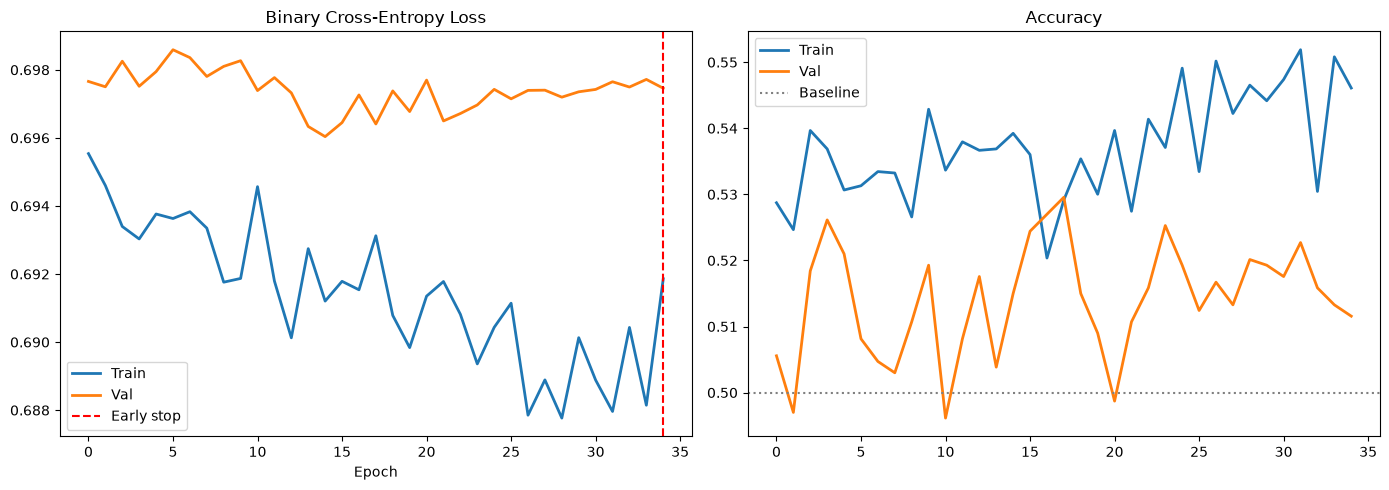

In [14]:
# Visualisation des courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['loss'], label='Train', lw=2)
ax1.plot(history.history['val_loss'], label='Val', lw=2)
ax1.axvline(x=len(history.history['loss']) - 1, color='red', ls='--', label='Early stop')
ax1.set_title('Binary Cross-Entropy Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train', lw=2)
ax2.plot(history.history['val_accuracy'], label='Val', lw=2)
ax2.axhline(y=0.5, color='gray', ls=':', label='Baseline')
ax2.set_title('Accuracy')
ax2.legend()

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

In [15]:
# STEP 5 : Prédictions & Métriques de classification
#Évaluation du modèle sur l'ensemble de test
y_proba = model.predict(Xte).flatten()
y_pred = (y_proba >= 0.5).astype(int)

#RAPPORT DE CLASSIFICATION (Seuil standard 0.5)
print(classification_report(yte, y_pred, target_names=['BAISSE (0)', 'HAUSSE (1)']))

auc = roc_auc_score(yte, y_proba)
print(f'AUC-ROC: {auc:.4f}')

cm = confusion_matrix(yte, y_pred)
print('Matrice de Confusion:')
print(f'  TN={cm[0,0]}  FP={cm[0,1]}')
print(f'  FN={cm[1,0]}  TP={cm[1,1]}')

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

  BAISSE (0)       0.54      0.53      0.53       609
  HAUSSE (1)       0.49      0.50      0.50       558

    accuracy                           0.51      1167
   macro avg       0.51      0.51      0.51      1167
weighted avg       0.52      0.51      0.52      1167

AUC-ROC: 0.5273
Matrice de Confusion:
  TN=322  FP=287
  FN=279  TP=279


In [16]:
#Calibration du seuil de décision pour le trading
print("\n6. Optimization du seuil de décision...")
thresholds = np.arange(0.30, 0.75, 0.05)
best_thresh = 0.5
best_prec = 0.0

for thresh in thresholds:
    pred = (y_proba >= thresh).astype(int)
    n_signals = pred.sum()
    if n_signals < 10:
        continue
    prec = (pred & yte).sum() / n_signals
    print(f'Seuil {thresh:.2f} → Précision: {prec:.2%} | Nb Trades: {n_signals}')
    if prec > best_prec:
        best_prec = prec
        best_thresh = thresh

TRADING_THRESHOLD = best_thresh
print(f"\nSeuil retenu pour le trading : {TRADING_THRESHOLD:.2f} (Précision: {best_prec:.2%})")


6. Optimization du seuil de décision...
Seuil 0.30 → Précision: 47.81% | Nb Trades: 1167
Seuil 0.35 → Précision: 47.81% | Nb Trades: 1167
Seuil 0.40 → Précision: 47.80% | Nb Trades: 1161
Seuil 0.45 → Précision: 49.08% | Nb Trades: 1082
Seuil 0.50 → Précision: 49.29% | Nb Trades: 566
Seuil 0.55 → Précision: 44.83% | Nb Trades: 58

Seuil retenu pour le trading : 0.50 (Précision: 49.29%)


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

Rendement cumulé Buy & Hold : 1.71%
Rendement cumulé Modèle (Net de frais) : -5.65%


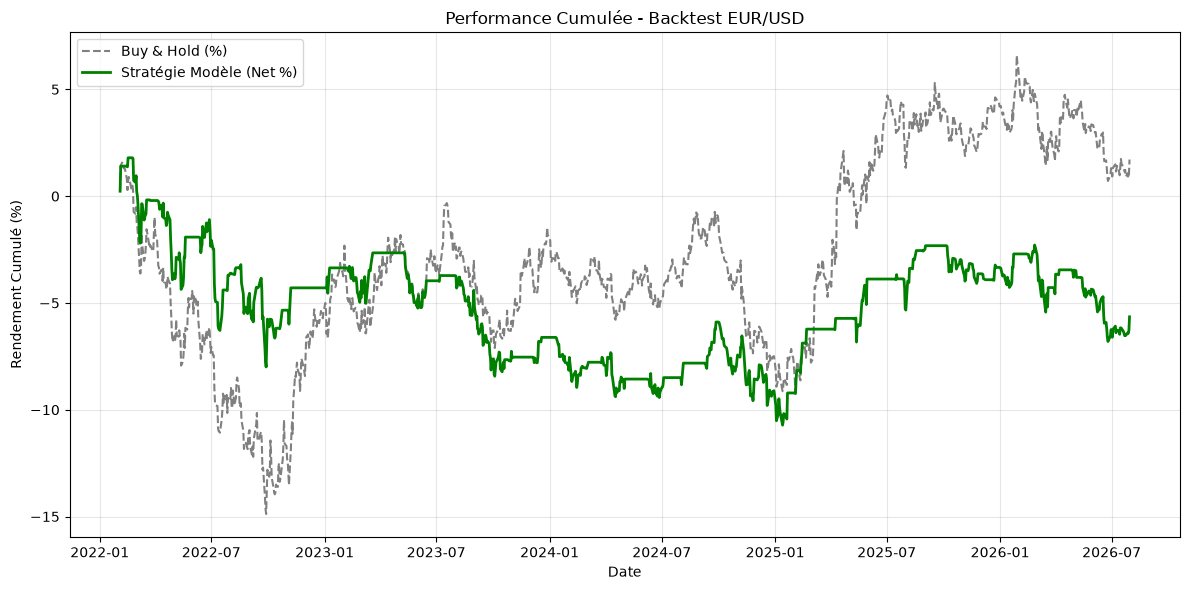

In [17]:
# Backtesting de la stratégie financière
df_test = df.iloc[split:].copy()
df_test['Signal'] = (model.predict(Xte).flatten() >= TRADING_THRESHOLD).astype(int)

# Calcul des retours
df_test['Return_BH'] = df_test['Close'].pct_change()
df_test['Return_Model'] = df_test['Signal'].shift(1) * df_test['Return_BH']

# Prise en compte des frais de transaction (spread ~0.03% par trade)
fee_per_trade = 0.0003
trades = df_test['Signal'].diff().abs()
df_test['Return_Net'] = df_test['Return_Model'] - (trades * fee_per_trade)

# Performances cumulées
cum_bh = (1 + df_test['Return_BH'].dropna()).cumprod() - 1
cum_model = (1 + df_test['Return_Net'].dropna()).cumprod() - 1

print(f"\nRendement cumulé Buy & Hold : {cum_bh.iloc[-1]:.2%}")
print(f"Rendement cumulé Modèle (Net de frais) : {cum_model.iloc[-1]:.2%}")

# Graphique de performance du backtest
plt.figure(figsize=(12, 6))
plt.plot(cum_bh.index, cum_bh.values * 100, label='Buy & Hold (%)', color='gray', linestyle='--')
plt.plot(cum_model.index, cum_model.values * 100, label='Stratégie Modèle (Net %)', color='green', lw=2)
plt.title('Performance Cumulée - Backtest EUR/USD')
plt.xlabel('Date')
plt.ylabel('Rendement Cumulé (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('backtest_performance.png', dpi=150)
plt.show()